# CreditRisk+ and the granularity adjustment

**Question:** What can the 1,120-name book lose according to CreditRisk+, which needs no simulation, and how much capital does the large-portfolio formula miss because the book is concentrated?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 03 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- describe the CreditRisk+ model, in which defaults are Poisson counts driven by a Gamma sector factor, and say how its loss distribution is computed without simulation;
- run the stable recursion on the illustrative book, check its first probability against a closed form, and read VaR and expected shortfall from the exact distribution;
- show on a constructed stress portfolio why the original Panjer-type recursion is kept only as a comparison;
- state the granularity adjustment of Gordy and Lutkebohmert, reproduce its test vector, and compute it for the book from the IRB capital of each group;
- read the gap between the infinitely granular formula and a finite, concentrated book, and say where the adjustment over-states it;
- test the recursion against a Monte Carlo sample of the same model.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import integrate, stats

# The notebook sits three folders below the repository root
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))


# Names of the validation lights
LIGHTS = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Two of the five loan-type files of case C10 (owner: this repository; the loss rates behind the fits come from the Federal Reserve's table `chgallsa`, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm, public domain, licence class `mirror-allowed`):

- `data/derived/C10/commercial-industrial.json`: the illustrative book of 1,120 names (`outputs.portfolio`), the committed CreditRisk+ rung (`outputs.rungs`, with its parameters and diagnostics), the granularity block (`outputs.granularity`) and the test row of the recursion against Monte Carlo (`tests`);
- `data/derived/C10/credit-cards.json`: the same blocks for the credit-card book, used in Step 5 because its granularity table carries the exact CreditRisk+ answer that the commercial file lacks.

The book is constructed and labelled `illustrative`, never a bank's. The next cell loads both files and prints the book and the CreditRisk+ parameters of the case.

In [2]:
# Load the two artifacts and print the book and the CreditRisk+ parameters of the case
doc = json.loads((ROOT / "data" / "derived" / "C10" / "commercial-industrial.json").read_text(encoding="utf-8"))
cards = json.loads((ROOT / "data" / "derived" / "C10" / "credit-cards.json").read_text(encoding="utf-8"))
out = doc["outputs"]
book = out["portfolio"]
groups = book["groups"]
pd_hat = out["fit"]["maximum_likelihood"]["pd"]["estimate"]
rho_hat = out["fit"]["maximum_likelihood"]["rho"]["estimate"]
rungs = {r["id"]: r for r in out["rungs"]}
parameters = {p["name"]: p["value"] for p in rungs["c4-creditrisk-plus"]["parameters"]}
diagnostics = {d["name"]: d["value"] for d in rungs["c4-creditrisk-plus"]["diagnostics"]}

print("book:", book["n_names"], "names,", f"{book['total_ead']:,.0f}", book["currency"])
print("loss unit:", parameters["loss_unit"], "| grid length:", int(diagnostics["n_max"]))

book: 1120 names, 100,000,000 USD
loss unit: 1000.0 | grid length: 12728


## Method

### Step 1: the CreditRisk+ model

CreditRisk+ is the actuarial counterpart of the copula models. Exposures are whole multiples $\nu_i$ of a **loss unit** (here 1,000 USD of loss, that is, exposure times LGD). The number of defaults of name $i$ is Poisson with an intensity that depends on a **sector factor** $S$ with a Gamma distribution of mean 1 and variance $\sigma^2$, and the portfolio loss in units is $X=\sum_i \nu_i Y_i$. With one sector and no idiosyncratic weight, the intensity of name $i$ is $p_i S$. The probability generating function of the loss, the object from which the distribution is computed, is (Haaf, Reiss and Schoenmakers, 2004, https://doi.org/10.21314/jor.2004.097):

$$G(z) = \exp\!\left(-\frac{1}{\sigma^2}\ln\!\left[1-\sigma^2\sum_i p_i\,(z^{\nu_i}-1)\right]\right)$$

The model has limits to remember: default mode only, deterministic recoveries in the basic model, and a Poisson approximation that can give several defaults of one obligor when a PD is large. The Gamma variance is a parameter the case sets by moment matching: $\sigma^2$ is the variance of the Vasicek default rate of notebook 01 over the squared PD, $\sigma^2=(E[p(Z)^2]-\mathrm{PD}^2)/\mathrm{PD}^2$. This is a calibration choice, not a risk measure. The next cell builds the engine's input from the groups, computes $\sigma^2$ by numerical integration of the conditional PD of notebook 01, and prints the exposure bands.

In [3]:
# Build the CreditRisk+ input from the groups and calibrate sigma squared by numerical integration
from riskvalidation.engines.vasicek import conditional_pd
from riskvalidation.portfolio import creditrisk_plus as cr

loss_unit, lgd = parameters["loss_unit"], book["lgd_mean"]
ead = np.concatenate([np.full(g["n_names"], g["ead_each"]) for g in groups])
pd_names = np.concatenate([np.full(g["n_names"], g["pd"]) for g in groups])
units = np.rint(ead * lgd / loss_unit).astype(int)

density = lambda z: float(conditional_pd(pd_hat, rho_hat, z)) ** 2 * stats.norm.pdf(z)
second_moment, _ = integrate.quad(density, -12, 12, epsabs=1e-16, epsrel=1e-12, limit=200)
sigma2 = (second_moment - pd_hat ** 2) / pd_hat ** 2
inp = cr.CreditRiskPlusInput(
    nu=units, pd=pd_names, w0=np.zeros(ead.size), weights=np.ones((ead.size, 1)),
    sigma2=np.array([sigma2]), loss_unit=loss_unit, currency=book["currency"])

print("names:", ead.size, "| exposure bands (loss units):", sorted(set(units.tolist())))
print("total units:", int(units.sum()), "| expected number of defaults:", round(float(pd_names.sum()), 4))
print("sigma^2 =", round(sigma2, 9))

names: 1120 | exposure bands (loss units): [9, 180, 900]
total units: 45000 | expected number of defaults: 16.2877
sigma^2 = 0.552065603


### Step 2: the stable recursion and its exact distribution

Taking logarithms of the generating function and expanding in powers of $z$ gives a recursion for the probabilities $p_n=P(X=n)$. Write $\ln G(z)=\sum_{j\ge 0} a_j z^j$; then $p_0=e^{a_0}$ and $n\,p_n=\sum_{j=1}^{n} j\,a_j\,p_{n-j}$. In the stable form of Haaf, Reiss and Schoenmakers (2004) every coefficient $a_j$ for $j\ge1$ is nonnegative, so no subtraction of terms of opposite sign occurs and no probability can come out negative. The engine's `pmf_stable` computes $p_0,\dots,p_{n_{\max}}$ and leaves the tail mass out. A closed form checks it: with one sector, $P(X=0)=G(0)=(1+\sigma^2\mu)^{-1/\sigma^2}$ where $\mu=\sum_i p_i$ is the expected number of defaults. `measures_from_pmf` then reads VaR and expected shortfall on the unit grid with the discrete Acerbi and Tasche estimator. The next cell runs the recursion on the grid of the case, checks $p_0$ and the missing mass, and reads the VaR and the expected shortfall at 99% and 99.9%.

In [4]:
# Run the stable recursion, check P(X = 0) against its closed form and read VaR and ES
n_max = int(diagnostics["n_max"])
pmf = cr.pmf_stable(inp, n_max)
mu = float(pd_names.sum())
print("n_max:", n_max, "| mass on the grid:", round(float(pmf.sum()), 12))
print("negative entries:", int((pmf < 0).sum()))
print("P(X = 0) recursion:", f"{pmf[0]:.12e}", "| closed form:", f"{(1 + sigma2 * mu) ** (-1 / sigma2):.12e}")

measures = cr.measures_from_pmf(pmf, loss_unit, (0.99, 0.999))
for m in measures:
    print(f"q = {m.level}: EL {m.el:,.0f} | VaR {m.var:,.0f} | ES {m.es:,.0f} | capital {m.ec:,.0f}")

n_max: 12728 | mass on the grid: 1.0
negative entries: 0
P(X = 0) recursion: 1.546187529037e-02 | closed form: 1.546187529037e-02
q = 0.99: EL 409,721 | VaR 2,079,000 | ES 2,514,778 | capital 1,669,279
q = 0.999: EL 409,721 | VaR 3,078,000 | ES 3,506,025 | capital 2,668,279


The recursion gives the whole distribution at once. The next cell draws its exceedance probability, the chance of a loss above each level, next to two references computed here: the Gaussian copula with one factor (a Monte Carlo of 200,000 scenarios) and the large-portfolio limit. CreditRisk+ with the moment-matched $\sigma^2$ and the Gaussian copula describe the same book with different assumptions, and the two curves are close in the body and part in the far tail.

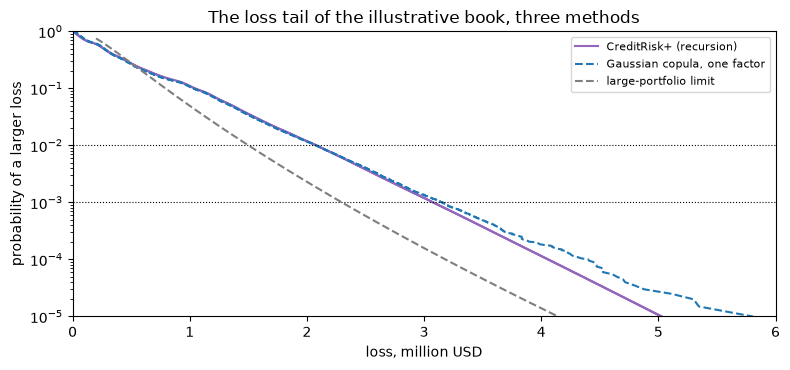

In [5]:
# Simulate the one-factor Gaussian copula and draw the loss tail of three methods
from riskvalidation.engines.vasicek import lhp_cdf
from riskvalidation.portfolio import copula
from riskvalidation.portfolio import portfolio as pf

one = pf.portfolio_from_groups(groups, book["currency"], book["lgd_gamma"], one_factor=True)
sim = rungs["c2-gaussian-1f"]["simulation"]
sample = copula.simulate_gaussian(one, 200_000, sim["seed"], sim["chunk_size"])
ordered = np.sort(sample.losses)
exceed_mc = 1.0 - np.arange(1, ordered.size + 1) / ordered.size
limit_loss = np.linspace(0.2, 6.0, 300) * 1e6
exceed_lhp = 1 - lhp_cdf(limit_loss / (book["total_ead"] * lgd), pd_hat, rho_hat)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(np.arange(pmf.size) * loss_unit / 1e6, 1 - np.cumsum(pmf), color="tab:purple", label="CreditRisk+ (recursion)")
ax.plot(ordered[:-1] / 1e6, exceed_mc[:-1], color="tab:blue", linestyle="--", label="Gaussian copula, one factor")
ax.plot(limit_loss / 1e6, exceed_lhp, color="tab:gray", linestyle="--", label="large-portfolio limit")
for q in (0.99, 0.999):
    ax.axhline(1 - q, color="black", linestyle=":", linewidth=0.8)
ax.set_yscale("log")
ax.set_ylim(1e-5, 1)
ax.set_xlim(0, 6)
ax.set_xlabel("loss, million USD")
ax.set_ylabel("probability of a larger loss")
ax.set_title("The loss tail of the illustrative book, three methods")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The purple curve is exact, with no sampling noise, and it is smooth all the way down to the 0.1% line where the simulated curve already becomes ragged. CreditRisk+ and the simulated Gaussian copula run close together, the first slightly under the second in the far tail, while both sit far to the right of the grey large-portfolio limit: the gap between the grey curve and the other two is the concentration of a book with about 104 effective names. The agreement is not a validation of either, since the two models share the PD and the correlation of the fit and differ in how defaults are generated. The picture does not say which tail a real book would have.

### Step 3: why the original recursion is kept only as a comparison

The recursion of the original CreditRisk+ document clears the denominators of the generating function by multiplying them out. That subtracts terms of opposite sign, and round-off can then give negative probabilities (the instability noted by Haaf, Reiss and Schoenmakers, 2004). The engine's `pmf_panjer` has the same signature as `pmf_stable` and is kept only to show this; it clips nothing. On the book of this case, with one sector, the two agree to rounding. The next cell compares them there and then on a **constructed stress portfolio**: 30,000 names in 5 exposure bands, 8 sectors with Gamma variances from 0.02 to 12, and about 1,800 expected defaults, drawn from a seeded generator. The stress portfolio is synthetic, built here to show the failure, and is not a case of the product.

In [6]:
# Compare the stable and the Panjer recursions on the case book and on a constructed stress portfolio
panjer = cr.pmf_panjer(inp, n_max)
gap = np.abs(panjer - pmf).max()
print("case book: largest difference", f"{gap:.1e}", "| negative Panjer entries:", int((panjer < 0).sum()))

rng = np.random.default_rng(3)
n_stress, n_sectors = 30_000, 8
stress_units = rng.integers(1, 6, size=n_stress)
stress_pd = rng.uniform(0.03, 0.09, size=n_stress)
stress_w = rng.dirichlet(np.ones(n_sectors + 1), size=n_stress)
stress = cr.CreditRiskPlusInput(
    nu=stress_units, pd=stress_pd, w0=stress_w[:, 0], weights=stress_w[:, 1:],
    sigma2=np.array([0.02, 0.2, 0.8, 1.5, 3.0, 6.0, 9.0, 12.0]), loss_unit=1.0, currency="USD")
stable_s = cr.pmf_stable(stress, 6000)
panjer_s = cr.pmf_panjer(stress, 6000)

print("stress portfolio:", n_stress, "names,", n_sectors, "sectors")
print("expected defaults:", round(float(stress.pd.sum())))
for label, p in (("stable", stable_s), ("Panjer", panjer_s)):
    outside = int(((p < 0) | (p > 1)).sum())
    print(f"{label:7s} entries outside [0, 1]: {outside} | negative: {int((p < 0).sum())} | sum: {p.sum():.3g}")

case book: largest difference 2.1e-17 | negative Panjer entries: 0
stress portfolio: 30000 names, 8 sectors
expected defaults: 1802
stable  entries outside [0, 1]: 0 | negative: 0 | sum: 0.721
Panjer  entries outside [0, 1]: 2406 | negative: 2406 | sum: -7.01


### Step 4: the granularity adjustment

The large-portfolio formula assumes names so small that the idiosyncratic risk disappears. A concentrated book keeps some of it, and capital must be higher. Gordy and Lutkebohmert (2013, https://www.ijcb.org/sites/default/files/journal/v9n3/ijcb-v9n3-granularity-adjustment-regulatory-capital-assessment.pdf) give a simplified adjustment, a share of exposure, built on the single-factor CreditRisk+ model with a Gamma factor of mean 1 and variance $1/\xi$:

$$\mathrm{GA}=\frac{1}{2K^*}\sum_i s_i^2\,C_i\,\big(\delta\,(K_i+R_i)-K_i\big),\qquad \delta=(\alpha_q-1)\left(\xi+\frac{1-\xi}{\alpha_q}\right)$$

where $s_i$ is the exposure share, $K_i$ the capital of name $i$ per unit of exposure, $K^*=\sum_i s_iK_i$, $R_i=E[\mathrm{LGD}_i]\,\mathrm{PD}_i$ the reserve, $C_i=(V[\mathrm{LGD}_i]+E[\mathrm{LGD}_i]^2)/E[\mathrm{LGD}_i]$, $V[\mathrm{LGD}_i]=\gamma\,E[\mathrm{LGD}_i](1-E[\mathrm{LGD}_i])$ and $\alpha_q$ the $q$-quantile of the Gamma factor (equations 11, 15, 16 and 17 of the paper). The paper states a test vector: $\xi=0.25$ and $q=0.999$ give $\delta=4.83$. The engine's `delta` and `gamma_quantile` compute it; the next cell reproduces the vector and shows how $\delta$ moves with $\xi$ and $q$.

In [7]:
# Compute the granularity constant delta for the paper test vector and for other precisions and levels
from riskvalidation.portfolio import granularity as gr

gran = out["granularity"]
xi_ref = gran["xi"]
alpha_ref = gr.gamma_quantile(xi_ref, 0.999)
print("xi =", xi_ref, "| q = 0.999 | alpha_q =", round(alpha_ref, 4), "| delta =", round(gr.delta(xi_ref, 0.999), 4))
print(f"{'xi':>6s} {'q = 0.99':>10s} {'q = 0.999':>10s} {'q = 0.9995':>11s}")
for xi in (0.25, 0.5, 1.0, 2.0):
    print(f"{xi:6.2f} {gr.delta(xi, 0.99):10.4f} {gr.delta(xi, 0.999):10.4f} {gr.delta(xi, 0.9995):11.4f}")

xi = 0.25 | q = 0.999 | alpha_q = 17.5058 | delta = 4.8336
    xi   q = 0.99  q = 0.999  q = 0.9995
  0.25     2.8568     4.8336      5.4482
  0.50     3.2421     5.3676      6.0166
  1.00     3.6052     5.9078      6.6009
  2.00     3.9396     6.4500      7.1987


The next cell draws delta as a function of the precision of the Gamma factor for three confidence levels.

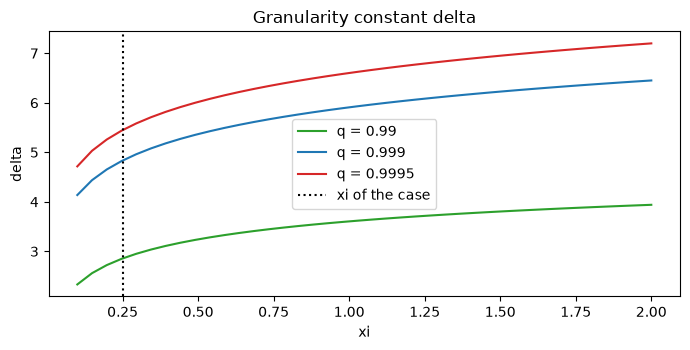

In [8]:
# Draw delta against xi for three confidence levels
xi_grid = np.linspace(0.1, 2.0, 40)
fig, ax = plt.subplots(figsize=(7, 3.6))
for level, color in ((0.99, "tab:green"), (0.999, "tab:blue"), (0.9995, "tab:red")):
    ax.plot(xi_grid, [gr.delta(x, level) for x in xi_grid], color=color, label=f"q = {level}")
ax.axvline(xi_ref, color="black", linestyle=":", label="xi of the case")
ax.set_xlabel("xi")
ax.set_ylabel("delta")
ax.set_title("Granularity constant delta")
ax.legend()
fig.tight_layout()
plt.show()

Delta grows with both arguments: a higher confidence level pushes the Gamma quantile out and a larger xi, which means a less volatile factor, makes the idiosyncratic part weigh more. At the xi of the case, 0.25, the curve for 99.9% passes through 4.83, the number the paper prints as its test vector, and the engine reproduces it to the printed digits. The picture only shows the constant; the size of the adjustment of a particular book also depends on its exposure shares, PDs and LGDs, which the next cell brings in. The Gamma model of the adjustment is an approximation of the Vasicek factor, so the constant is a regulatory choice and not an estimate.

Now the adjustment for the book. The capital $K_i$ of each name is the IRB capital of the name's group at its own PD, with an LGD of 45% and a maturity of 2.5 years (Basel Framework CRE31, https://www.bis.org/basel_framework/chapter/CRE/31.htm), as the regulatory algorithm of the paper prescribes. The engine's `capital_requirement` returns it and `granularity_adjustment` applies the formula, with the paper's $\xi=0.25$ and $\gamma=0.25$ read from the artifact. The adjustment is a share of exposure; adding it to the large-portfolio VaR gives the capital of the book with its concentration.

In [9]:
# Compute the granularity adjustment of the book from the IRB capital of each group
from riskvalidation.portfolio.portfolio import lhp_measures
from riskvalidation.regulatory.irb import capital_requirement

k_group = {}
for g in groups:
    k_group[g["id"]] = float(capital_requirement("corporate", g["pd"], lgd, regime="basel3", maturity=2.5).k)
k_names = np.concatenate([np.full(g["n_names"], k_group[g["id"]]) for g in groups])
share = ead / ead.sum()
print("K by group (IRB capital per unit of exposure):", {k: round(v, 5) for k, v in k_group.items()})

adjustment = {}
for level in (0.99, 0.999):
    res = gr.granularity_adjustment(share, k_names, pd_names, np.full(ead.size, lgd), gran["gamma"], gran["xi"], level)
    var_lhp = lhp_measures(book["total_ead"], lgd, pd_hat, rho_hat, (level,))[0].var
    adjustment[level] = (res.ga * book["total_ead"], var_lhp)
    print(f"q = {level}: delta {res.delta:.4f} | K* {res.k_star:.6f} | GA {res.ga:.8f}")
    print(f"        GA in money: {res.ga * book['total_ead']:,.0f} | large-portfolio VaR: {var_lhp:,.0f}")
    print(f"        GA over the large-portfolio VaR: {res.ga * book['total_ead'] / var_lhp:.3f}")

K by group (IRB capital per unit of exposure): {'g-large': 0.05598, 'g-mid': 0.07416, 'g-small': 0.08477}
q = 0.99: delta 2.8568 | K* 0.069012 | GA 0.00481771
        GA in money: 481,771 | large-portfolio VaR: 1,500,956
        GA over the large-portfolio VaR: 0.321
q = 0.999: delta 4.8336 | K* 0.069012 | GA 0.00982976
        GA in money: 982,976 | large-portfolio VaR: 2,298,833
        GA over the large-portfolio VaR: 0.428


### Step 5: the adjustment against the exact answer for a finite book

The adjustment is an asymptotic approximation, proportional to the HHI of exposure shares, so for $n$ identical names $\mathrm{GA}\times n$ is constant. How good is it for a small book? For $n$ identical names the single-factor CreditRisk+ model of the paper can be solved exactly with the recursion: the weight of the names on the factor is $\omega=K/(E[\mathrm{LGD}]\,\mathrm{PD}\,(\alpha_q-1))$ (equation 13 of the paper, solved for $\omega$), the Gamma variance is $1/\xi$, and the exact adjustment is the difference between the book's exact VaR share, $E[\mathrm{LGD}]\,\mathrm{VaR}_{\text{units}}/n$, and the infinitely granular one, $E[\mathrm{LGD}]\,\mathrm{PD}+K$. The condition is $0<\omega\le1$. For the commercial book $\omega$ is above 1, so the recursion cannot be run for it; the credit-card book satisfies it. The next cell computes, for credit cards, the adjustment and the exact gap for $n=10$, $100$ and $1{,}000$ names, and the commercial $\omega$.

In [10]:
# For n identical credit-card names compare the adjustment with the exact CreditRisk+ gap
c_out = cards["outputs"]
pd_cards = c_out["fit"]["maximum_likelihood"]["pd"]["estimate"]
asset_class = c_out["irb_reference"]["asset_class"]
k_cards = float(capital_requirement(asset_class, pd_cards, lgd, regime="basel3").k)
xi, level = gran["xi"], 0.999
alpha = gr.gamma_quantile(xi, level)
omega = k_cards / (lgd * pd_cards * (alpha - 1.0))
print("credit cards: PD", round(pd_cards, 5), "| K", round(k_cards, 5), "| omega", round(omega, 3))

print(f"{'names':>7s} {'GA ' + '(formula)':>14s} {'GA x n':>9s} {'exact gap':>14s} {'formula / exact':>18s}")
for n_names in (10, 100, 1000):
    ones = np.ones(n_names)
    formula = gr.granularity_adjustment(
        ones / n_names, k_cards * ones, pd_cards * ones, lgd * ones, gran["gamma"], xi, level).ga
    names = cr.CreditRiskPlusInput(
        nu=np.ones(n_names, dtype=np.int64), pd=pd_cards * ones, w0=(1.0 - omega) * ones,
        weights=omega * ones[:, None], sigma2=np.array([1.0 / xi]), loss_unit=1.0, currency="USD")
    grid = max(40, 4 * n_names)
    pmf_n = cr.pmf_stable(names, grid)
    while pmf_n.sum() < level + 1e-6 and grid < 20 * n_names:
        grid *= 2
        pmf_n = cr.pmf_stable(names, grid)
    var_units = cr.measures_from_pmf(pmf_n, 1.0, (level,))[0].var
    exact = max(lgd * var_units / n_names - (lgd * pd_cards + k_cards), 0.0)
    print(f"{n_names:7d} {formula:14.6f} {formula * n_names:9.4f} {exact:14.6f} {formula / exact:18.2f}")

k_commercial = float(capital_requirement("corporate", pd_hat, lgd, regime="basel3", maturity=2.5).k)
print("commercial: omega implied by K:", round(k_commercial / (lgd * pd_hat * (alpha - 1.0)), 3))

credit cards: PD 0.04228 | K 0.03917 | omega 0.125
  names   GA (formula)    GA x n      exact gap    formula / exact
     10       0.181580    1.8158       0.121804               1.49
    100       0.018158    1.8158       0.013804               1.32
   1000       0.001816    1.8158       0.001204               1.51
commercial: omega implied by K: 1.055


### Step 6: the recursion against a Monte Carlo of the same model

The exact distribution should agree with a simulation of the same Poisson-Gamma model. The engine's `crp_recursion_vs_mc` measures the Kolmogorov distance between the recursion's distribution function and a sample's, with the asymptotic Kolmogorov law for its p-value (conservative for a discrete distribution, the contract's definition); it is red whatever the p-value if any probability is negative. The comparator is a plain simulation written here from the model's definition, an independent check and not a second engine: draw the Gamma factor, and for each group draw a Poisson count with intensity (names times PD times factor) and multiply by the group's loss units. The next cell draws 100,000 scenarios of that simulation and tests the recursion against them.

In [11]:
# Simulate the Poisson-Gamma model and test the recursion against the sample
from riskvalidation.validation.portfolio import crp_recursion_vs_mc

rng_crp = np.random.default_rng(np.random.PCG64(4006))
n_mc = 100_000
factor = rng_crp.gamma(shape=1.0 / sigma2, scale=sigma2, size=n_mc)
sample_units = np.zeros(n_mc, dtype=np.int64)
first = 0
for g in groups:
    sample_units += int(units[first]) * rng_crp.poisson(g["n_names"] * g["pd"] * factor)
    first += g["n_names"]

verdict = crp_recursion_vs_mc(pmf, sample_units, model_id="m-creditrisk-plus")
print("scenarios:", n_mc, "| Kolmogorov distance:", round(verdict.statistic, 5))
print("p-value:", round(verdict.p_value, 4), "| light:", LIGHTS[verdict.light.value])
print("negative entries:", verdict.extras["negative_entries"])

scenarios: 100000 | Kolmogorov distance: 0.00398
p-value: 0.0843 | light: green
negative entries: 0


The next cell draws the difference between the distribution function of the recursion and the empirical one of the sample, with the 5% band of the Kolmogorov distance.

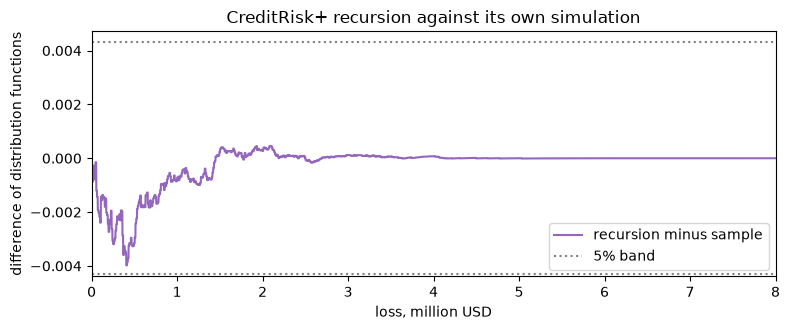

In [12]:
# Draw the difference between the recursion and the sample distribution functions
counts = np.bincount(np.minimum(sample_units, pmf.size - 1), minlength=pmf.size)
difference = np.cumsum(pmf) - np.cumsum(counts) / n_mc
band = 1.36 / np.sqrt(n_mc)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(np.arange(pmf.size) * loss_unit / 1e6, difference, color="tab:purple", label="recursion minus sample")
ax.axhline(band, color="gray", linestyle=":", label="5% band")
ax.axhline(-band, color="gray", linestyle=":")
ax.set_xlim(0, 8)
ax.set_xlabel("loss, million USD")
ax.set_ylabel("difference of distribution functions")
ax.set_title("CreditRisk+ recursion against its own simulation")
ax.legend()
fig.tight_layout()
plt.show()

The curve wanders around zero and stays inside the dotted band, which is the width that sampling noise alone would produce with 100,000 scenarios. Its largest excursion is the Kolmogorov distance printed above, and the test turns green because no excursion leaves the band. The two computations share the Poisson-Gamma model and nothing else: the recursion is exact arithmetic on a generating function and the sample is random draws, so agreement means the recursion implements the model it claims to implement. It does not mean the model fits real defaults, and the test would turn red at once if one probability were negative.

The last cell puts the methods side by side. For the same book and the same fitted PD and correlation it takes the 99.9% VaR of the large-portfolio limit, of CreditRisk+, of the Gaussian copula by Monte Carlo and of the limit plus the granularity adjustment, and draws them as bars. The gap between the first and the others is the price of a finite, concentrated book.

method                                          VaR 99.9%   ratio to the limit
Large-portfolio limit                           2,298,833                1.000
CreditRisk+                                     3,078,000                1.339
Gaussian copula, Monte Carlo                    3,150,000                1.370
Limit + granularity adjustment                  3,281,809                1.428


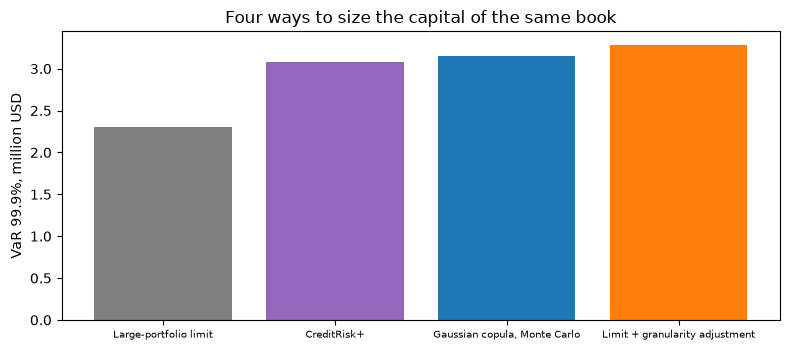

In [13]:
# Compare the 99.9% VaR of four methods on the same book
ga_money, var_limit = adjustment[0.999]
var_mc = pf.measures_from_sample(sample.losses, (0.999,), pf.expected_loss(one))[0].var
comparison = {
    "Large-portfolio limit": var_limit,
    "CreditRisk+": measures[1].var,
    "Gaussian copula, Monte Carlo": var_mc,
    "Limit + granularity adjustment": var_limit + ga_money,
}
print(f"{'method':44s} {'VaR 99.9%':>12s} {'ratio to the limit':>20s}")
for name, value in comparison.items():
    print(f"{name:44s} {value:12,.0f} {value / var_limit:20.3f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
colors = ["tab:gray", "tab:purple", "tab:blue", "tab:orange"]
ax.bar(range(len(comparison)), np.array(list(comparison.values())) / 1e6, color=colors)
ax.set_xticks(range(len(comparison)), list(comparison), fontsize=7)
ax.set_ylabel("VaR 99.9%, million USD")
ax.set_title("Four ways to size the capital of the same book")
fig.tight_layout()
plt.show()

The first bar is what the closed formula says and the other three are what a finite, concentrated book needs. CreditRisk+, the simulated Gaussian copula and the limit plus the adjustment all land between 3.0 and 3.3 million USD, about a third higher than the formula, so the three different routes agree on the size of the concentration effect even though they share nothing but the PD and the correlation. The adjustment is the one that needs no simulation and no recursion, a single formula on the exposure shares, which is why a supervisor can use it. The bars do not rank the methods: each rests on a different dependence assumption, and the real tail of a bank book is not known.

## Results

**Answer:** CreditRisk+ puts the 99.9% value at risk of the 1,120-name book at 3,078,000 USD (capital of 2,668,279 USD) without any simulation, a third above the large-portfolio limit of 2,298,833 USD, and the granularity adjustment of 982,976 USD at 99.9% accounts for that concentration, taking the limit to 3,281,809 USD.

- **The recursion gives the whole loss distribution exactly, and its anchor holds.** For the 1,120-name book the stable recursion puts mass 1.0 on a grid of 12,728 units with no negative entry, and its first probability, 1.546187529037e-02, equals the closed form $(1+\sigma^2\mu)^{-1/\sigma^2}$ to the digits printed, with $\sigma^2=0.552066$ obtained by integrating the conditional PD of notebook 01. The 99% and 99.9% VaR are 2,079,000 and 3,078,000 USD and the expected shortfall 2,514,778 and 3,506,025 USD.
- **CreditRisk+ and the Gaussian copula agree on the body and part slightly in the tail.** The two curves of the figure run together up to the 0.1% line; the actuarial one is a little lower in the far tail. Both are far above the large-portfolio limit, because the book is concentrated.
- **The original recursion fails where the stable one does not.** On the case book the Panjer and the stable recursion agree to 2.1e-17. On the constructed stress portfolio of 30,000 names and 8 sectors the stable recursion keeps every entry inside [0, 1] while the Panjer recursion produces 2,406 negative entries and probabilities that add up to -7.01. That is why the engine uses the stable recursion for its capital and keeps the original only as a comparison.
- **The granularity adjustment adds about a third to the large-portfolio capital.** With the paper's $\xi=0.25$, $\delta=4.8336$ at 99.9%, the adjustment is 481,771 USD at 99% and 982,976 USD at 99.9%, 0.428 of the large-portfolio VaR at 99.9%. The large-portfolio VaR plus the adjustment is 3,281,809 USD, in the range of the other two methods.
- **The adjustment overstates the exact gap for small books.** For credit-card books of 10, 100 and 1,000 names, the formula gives 1.49, 1.32 and 1.51 times the exact CreditRisk+ gap; GA times n is constant at 1.8158, as the HHI proportionality says. For the commercial book the weight implied on the systematic factor is 1.055, outside (0, 1], so no exact answer exists there: the comparison is a property of the model assumptions, not a flaw of the engine.
- **The recursion matches its own simulation.** Against 100,000 scenarios the Kolmogorov distance is 0.00398, p = 0.0843 and green, with no negative entry. The test certifies the implementation of the model, not the model.

What this notebook does not show: how the capital splits among names and groups (notebook 05), which dependence structure real banks have, or the uncertainty of the correlation behind every number. The book is illustrative, never a bank's.

## Summary

- CreditRisk+ models defaults as Poisson counts driven by a Gamma factor; its loss distribution comes from a recursion on the generating function, with no simulation, and `pmf_stable` is exact and nonnegative.
- The original Panjer recursion subtracts terms of opposite sign and fails on a large multi-sector portfolio; the engine keeps it only as a comparison.
- The granularity adjustment (`granularity_adjustment`, `delta`) reproduces the paper's test vector and adds 42.8% to the large-portfolio VaR of the book at 99.9%.
- Against the exact CreditRisk+ gap of identical names, the formula over-states by 32% to 51% on the credit-card book, and a book whose implied factor weight is outside (0, 1] has no exact answer.
- `crp_recursion_vs_mc` tests the recursion against a simulation of its own model.

**What to try next.** Change the number of names in Step 5 to 20 and 500 for credit cards and compare the formula with the exact gap. Then open notebook 05, where the capital of the book is split among its groups.

## References

- Haaf, H., Reiss, O. and Schoenmakers, J. (2004), Numerically stable computation of CreditRisk+, Journal of Risk 6(4):1-10. https://doi.org/10.21314/jor.2004.097
- Gordy, M. B. and Lutkebohmert, E. (2013), Granularity adjustment for regulatory capital assessment, International Journal of Central Banking 9(3):33-48. https://www.ijcb.org/sites/default/files/journal/v9n3/ijcb-v9n3-granularity-adjustment-regulatory-capital-assessment.pdf
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3):199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- BCBS, Basel Framework, CRE31: IRB approach, risk weight functions for corporate, bank, sovereign and retail exposures. https://www.bis.org/basel_framework/chapter/CRE/31.htm
- Acerbi, C. and Tasche, D. (2002), On the coherence of expected shortfall, Journal of Banking and Finance 26(7):1487-1503. https://doi.org/10.1016/S0378-4266(02)00283-2
- Federal Reserve charge-off table `chgallsa`, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm (public domain; licence class mirror-allowed).
- Credit Suisse First Boston (1997), CreditRisk+: A Credit Risk Management Framework, the original model document: not accessed by the persisted research (UNVERIFIED primary); the model statement is verified from Haaf, Reiss and Schoenmakers (2004).
- Persisted research dossier 04 of this product (credit-risk models, state of the art), sections H.4 and H.5 (CreditRisk+ and the granularity adjustment).
- The engine's contract for these functions: `docs/contracts/engine/` of this repository.